In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset, Subset
from torchvision import datasets, transforms, models  # add model to the list
from torchvision.utils import make_grid

import os


import numpy as np
import pandas as pd

import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt

%matplotlib inline


from linear_size import linear_size_inputsize


In [2]:
torch.cuda.is_available()

True

In [3]:
torch.cuda.get_device_name(0)

'NVIDIA GeForce RTX 5080'

In [4]:
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose(
    [
        transforms.RandomRotation(10),
        transforms.RandomHorizontalFlip(),
        transforms.Resize(224),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ]
)

test_transform = transforms.Compose(
    [
        transforms.Resize(224),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ]
)

In [5]:
root = "./Data/CATS_DOGS"

train_data = datasets.ImageFolder(
    os.path.join(root, "train"),
    transform=train_transform,
)
test_data = datasets.ImageFolder(os.path.join(root, "test"), transform=test_transform)


In [6]:
# generator = torch.Generator().manual_seed(42)

# train_indices = torch.randperm(len(train_data), generator=generator)
# train_subset = Subset(train_data, train_indices.tolist())


# test_indices = torch.randperm(len(test_data), generator=generator)
# test_subset = Subset(test_data, test_indices.tolist())


In [7]:
# torch.randperm(10, generator=generator)

In [8]:
type(test_data[0])

tuple

In [9]:
# test_data = TensorDataset(
#     np.array(test_data)[0].cuda(),
#     np.array(test_data)[1].cuda()
# )

In [10]:
class_name = np.array(train_data.classes)
class_name

array(['CAT', 'DOG'], dtype='<U3')

In [11]:
X_train = []
y_train = []

for i, (X, y) in enumerate(train_data):
    X_train.append(X)
    y_train.append(y)

In [12]:
print(y_train)
print(len(y_train))


[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 

In [13]:
X_test = []
y_test = []
for i, (X, y) in enumerate(test_data):
    X_test.append(X)
    y_test.append(y)

In [14]:
print(X.type())
print(type(y))

torch.FloatTensor
<class 'int'>


In [15]:
# len(y_train)

In [16]:
# device = torch.device("cuda")

# images = []
# labels = []

# for image, label in dataset:
#     images.append(image)
#     labels.append(label)

# images = torch.stack(images).to(device)
# labels = torch.tensor(labels).to(device)

In [17]:
# train_data = TensorDataset(
#     torch.tensor(np.array(X_train), dtype=torch.float16).cuda(),
#     torch.tensor(np.array(y_train), dtype=torch.long).cuda(),
# )
# test_data = TensorDataset(
#     torch.tensor(np.array(X_test), dtype=torch.float16).cuda(),
#     torch.tensor(np.array(y_test), dtype=torch.long).cuda(),
# )


X_train = torch.tensor(np.array(X_train)).cuda()
y_train = torch.tensor(np.array(y_train)).cuda()
train_data = TensorDataset(
    X_train,
    y_train,
)


X_test = torch.tensor(np.array(X_test)).cuda()
y_test = torch.tensor(np.array(y_test)).cuda()
test_data = TensorDataset(
    X_test,
    y_test,
)

print(X_train.type())
print(y_train.type())
print(X_test.type())
print(y_test.type())


torch.cuda.FloatTensor
torch.cuda.LongTensor
torch.cuda.FloatTensor
torch.cuda.LongTensor


In [18]:
# torch.manual_seed(42)
batch_size = 10

# train_loader = DataLoader(
#     train_data, batch_size=batch_size, shuffle=True, num_workers=0, pin_memory=True
# )
# test_loader = DataLoader(
#     test_data, batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=True
# )
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)


In [19]:
print(torch.cuda.memory_allocated() / 1024**3)
print(torch.cuda.memory_reserved() / 1024**3)

14.016379833221436
14.01953125


In [20]:
len(test_data)

6251

In [21]:
# import torch

# print("PyTorch:", torch.__version__)
# print("CUDA:", torch.version.cuda)
# print("CUDA available:", torch.cuda.is_available())

# free, total = torch.cuda.mem_get_info()

# print("\nGPU Memory:")
# print("Total:", round(total / 1024**3, 2), "GiB")
# print("Free:", round(free / 1024**3, 2), "GiB")
# print("Used:", round((total-free) / 1024**3, 2), "GiB")

# print("\nPyTorch Memory:")
# print("Allocated:",
#       round(torch.cuda.memory_allocated() / 1024**3, 2), "GiB")

# print("Reserved:",
#       round(torch.cuda.memory_reserved() / 1024**3, 2), "GiB")

# print("Peak Allocated:",
#       round(torch.cuda.max_memory_allocated() / 1024**3, 2), "GiB")

In [22]:
# print("X_train:")
# print("Shape:", X_train.shape)
# print("Dtype:", X_train.dtype)
# print("Device:", X_train.device)

# print("\ny_train:")
# print("Shape:", y_train.shape)
# print("Dtype:", y_train.dtype)
# print("Device:", y_train.device)

# print("\nModel:")
# print("Parameters:", sum(
#     p.numel() for p in model.parameters()
# ))

# print("Model device:", next(model.parameters()).device)
# print("Model dtype:", next(model.parameters()).dtype)

In [23]:
for images, labels in train_loader:
    print(images.device)
    break

cuda:0


In [24]:
images.shape

torch.Size([10, 3, 224, 224])

In [25]:
# im = make_grid(images, nrow=5)
# mean_inv = [-m / s for m, s in zip(mean, std)]
# std_inv = [1 / s for s in std]

# inv_normalize = transforms.Normalize(mean=mean_inv, std=std_inv)

# im_inv = inv_normalize(im)

# print("LABELS: ", class_name[labels])
# plt.figure(figsize=(12, 4))
# plt.imshow(im_inv.permute(1, 2, 0))

In [26]:
# linear_size_inputsize(
#     (224, 224),
#     (3, 2, 3, 2, 3, 2, 3, 2),
#     (1, 2, 1, 2, 1, 2, 1, 2),
#     (0, 0, 0, 0, 0, 0, 0, 0),
# )

In [27]:
class ConvolutionaNetwork_CATS_DOGS(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 6, 3)
        self.drop1 = nn.Dropout()
        self.conv2 = nn.Conv2d(6, 16, 3)
        self.drop2 = nn.Dropout()
        self.conv3 = nn.Conv2d(16, 26, 3)
        self.drop3 = nn.Dropout()
        self.conv4 = nn.Conv2d(26, 36, 3)
        self.drop4 = nn.Dropout()
        self.fc1 = nn.Linear(
            linear_size_inputsize(
                (224, 224),
                (3, 2, 3, 2, 3, 2, 3, 2),
                (1, 2, 1, 2, 1, 2, 1, 2),
                (0, 0, 0, 0, 0, 0, 0, 0),
            )
            * 36,
            120,
        )
        self.drop3 = nn.Dropout()
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 2)

    def forward(self, X):
        X = self.drop1(F.relu(self.conv1(X)))
        X = F.max_pool2d(X, 2, 2)
        X = self.drop2(F.relu(self.conv2(X)))
        X = F.max_pool2d(X, 2, 2)
        X = self.drop3(F.relu(self.conv3(X)))
        X = F.max_pool2d(X, 2, 2)
        X = self.drop4(F.relu(self.conv4(X)))
        X = F.max_pool2d(X, 2, 2)
        X = X.view(len(X), -1)
        X = self.drop3(F.relu(self.fc1(X)))
        X = F.relu(self.fc2(X))
        X = self.fc3(X)

        return X

In [28]:
class ConvolutionaNetwork2(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 6, 3)
        self.conv2 = nn.Conv2d(6, 16, 3)
        self.conv3 = nn.Conv2d(16, 26, 3)
        self.conv4 = nn.Conv2d(26, 36, 3)
        self.fc1 = nn.Linear(12 * 12 * 36, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 2)

    def forward(self, X):
        X = F.relu(self.conv1(X))
        X = F.max_pool2d(X, 2, 2)
        X = F.relu(self.conv2(X))
        X = F.max_pool2d(X, 2, 2)
        X = F.relu(self.conv3(X))
        X = F.max_pool2d(X, 2, 2)
        X = F.relu(self.conv4(X))
        X = F.max_pool2d(X, 2, 2)
        X = X.view(len(X), -1)
        X = F.relu(self.fc1(X))
        X = F.relu(self.fc2(X))
        X = self.fc3(X)

        return X

In [29]:
((54 - 2) / 2 - 2) / 2

12.0

In [30]:
torch.manual_seed(101)

# CNNmodel = ConvolutionaNetwork_CATS_DOGS().cuda().half()
CNNmodel = ConvolutionaNetwork_CATS_DOGS().cuda()
criterion = nn.CrossEntropyLoss()
optimizers = torch.optim.Adam(CNNmodel.parameters(), lr=0.001)
next(CNNmodel.parameters()).is_cuda

True

In [41]:
cal = 0
kernel_size = [12, 15]
kernel_size[cal]
isinstance(kernel_size[cal], int)
# kernel_size[cal][0]


True

In [32]:
total = 0

for name, param in CNNmodel.named_parameters():
    print(name, param.shape)
    total += param.numel()

print(total)

conv1.weight torch.Size([6, 3, 3, 3])
conv1.bias torch.Size([6])
conv2.weight torch.Size([16, 6, 3, 3])
conv2.bias torch.Size([16])
conv3.weight torch.Size([26, 16, 3, 3])
conv3.bias torch.Size([26])
conv4.weight torch.Size([36, 26, 3, 3])
conv4.bias torch.Size([36])
fc1.weight torch.Size([120, 5184])
fc1.bias torch.Size([120])
fc2.weight torch.Size([84, 120])
fc2.bias torch.Size([84])
fc3.weight torch.Size([2, 84])
fc3.bias torch.Size([2])
645812


In [33]:
import time

start_time = time.time()

# Limits on num of batches
max_trn_batch = 800  # batch 10 images --> 8000 images
max_tst_batch = 300  # 3000 max images


# variables
epochs = 20
train_losses = []
test_losses = []
train_correct = []
test_correct = []

# For loop epochs
for i in range(epochs):
    trn_corr = 0
    tst_corr = 0

    # train
    for b, (X_train, y_train) in enumerate(train_loader):
        # Optinal limit number of batch
        # if b == max_trn_batch:
        #     break
        # print(X_train.device)
        # X_train = X_train.cuda()
        # X_train = X_train.to("cuda", non_blocking=True)
        # print(X_train.device)
        # y_train = y_train.cuda()
        # y_train = y_train.to("cuda", non_blocking=True)
        b += 1

        y_pred = CNNmodel(X_train)  # no flatten
        loss = criterion(y_pred, y_train)
        predicted = torch.max(y_pred.data, 1)[1]
        trn_corr += (predicted == y_train).sum()

        optimizers.zero_grad()
        loss.backward()
        optimizers.step()

        if b % 200 == 0:
            # print(predicted, y_train)
            acc = trn_corr * 100 / len(X_train) / b
            print(
                f"Epoch: {i + 1:2} Batch: {b:4} [{len(X_train) * b}/{len(train_data)}] loss: {loss.item():2.8f} accuracy: {acc:2.2f}%"
            )

    train_losses.append(loss.item())
    train_correct.append(trn_corr.item())

    # validation
    with torch.no_grad():
        for b, (X_test, y_test) in enumerate(test_loader):
            # if b == max_tst_batch:
            #     break
            b += 1
            # X_test = X_test.cuda()
            # X_test = X_test.to("cuda", non_blocking=True)
            # y_test = y_test.cuda()
            # y_test = y_test.to("cuda", non_blocking=True)

            y_val = CNNmodel(X_test)
            predicted = torch.max(y_val.data, 1)[1]
            tst_corr += (predicted == y_test).sum()

            if b % 200 == 0:
                # print(predicted, y_test)
                acc = tst_corr * 100 / len(X_test) / b
                print(
                    f"[{len(X_test) * b}/{len(test_data)}] {tst_corr} accuracy: {acc:2.2f}%"
                )

    loss = criterion(y_val, y_test)
    test_losses.append(loss.item())
    test_correct.append(tst_corr.item())

during = time.time() - start_time
mins = during // 60
secs = during - mins * 60
print(f"Traning took {mins:2.0f}:{secs:2.0f}")

Epoch:  1 Batch:  200 [2000/18743] loss: 0.79253423 accuracy: 49.65%
Epoch:  1 Batch:  400 [4000/18743] loss: 0.68667924 accuracy: 50.65%
Epoch:  1 Batch:  600 [6000/18743] loss: 0.62751901 accuracy: 51.60%
Epoch:  1 Batch:  800 [8000/18743] loss: 0.63631582 accuracy: 52.62%
Epoch:  1 Batch: 1000 [10000/18743] loss: 0.61268681 accuracy: 52.95%
Epoch:  1 Batch: 1200 [12000/18743] loss: 1.13983166 accuracy: 53.69%
Epoch:  1 Batch: 1400 [14000/18743] loss: 0.68999261 accuracy: 54.14%
Epoch:  1 Batch: 1600 [16000/18743] loss: 0.60508913 accuracy: 55.21%
Epoch:  1 Batch: 1800 [18000/18743] loss: 0.63981920 accuracy: 55.64%
[2000/6251] 1011 accuracy: 50.55%
[4000/6251] 2171 accuracy: 54.27%
[6000/6251] 3589 accuracy: 59.82%
Epoch:  2 Batch:  200 [2000/18743] loss: 0.66798002 accuracy: 62.40%
Epoch:  2 Batch:  400 [4000/18743] loss: 0.52001250 accuracy: 62.05%
Epoch:  2 Batch:  600 [6000/18743] loss: 0.63881433 accuracy: 61.43%
Epoch:  2 Batch:  800 [8000/18743] loss: 0.69909334 accuracy: 61.

In [34]:
# torch.save(CNNmodel, "./models/CNNCATS_DOGS_16_000imagesDataset_20epoches.pt")
# torch.save(CNNmodel, "./models/CNNCATS_DOGS_fullDAtaset_10epochs.pt")

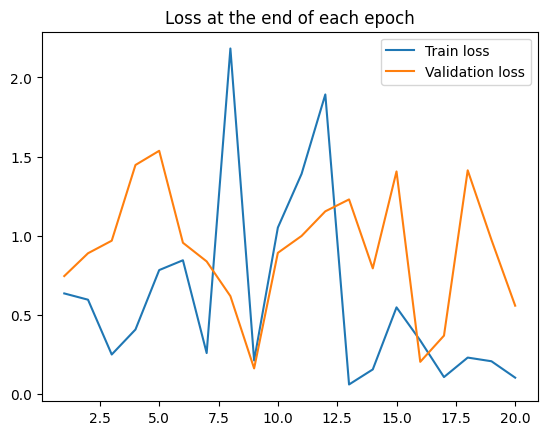

In [35]:
plt.plot(range(1, epochs + 1), train_losses, label="Train loss")
plt.plot(range(1, epochs + 1), test_losses, label="Validation loss")
plt.title("Loss at the end of each epoch")
plt.legend();

In [36]:
max_tst_batch * batch_size

3000

In [37]:
# np.array([item.to("cpu") for item in test_correct])
test_correct
# np.array([item.item() for item in test_correct])

[3773,
 4428,
 4679,
 4736,
 4782,
 4989,
 4944,
 5039,
 4969,
 5097,
 5082,
 5116,
 5022,
 5035,
 5128,
 4981,
 5117,
 5134,
 5146,
 5101]

In [38]:
# print(item for item in train_correct)

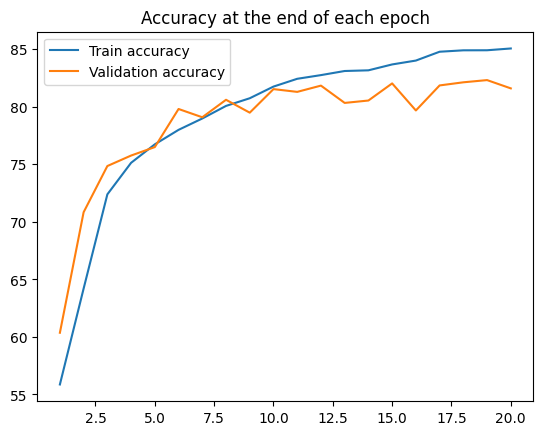

In [39]:
train_acc = np.array([item for item in train_correct]) * 100 / len(train_data)
test_acc = np.array([item for item in test_correct]) * 100 / len(test_data)

plt.plot(range(1, epochs + 1), train_acc, label="Train accuracy")
plt.plot(range(1, epochs + 1), test_acc, label="Validation accuracy")
plt.title("Accuracy at the end of each epoch")
plt.legend();

In [40]:
# train_acc = np.array(train_correct) * 100 / max_trn_batch / batch_size
# test_acc = np.array(test_correct) * 100 / max_tst_batch / batch_size

# train_acc = np.array(train_correct) * 100 / len(train_data)
# test_acc = np.array(test_correct) * 100 / len(test_data)
# train_acc = np.array([item for item in train_correct]) * 100 / len(train_data)
# test_acc = np.array([item for item in test_correct]) * 100 / len(test_data)

# plt.plot(range(1, epochs + 1), train_acc, label="Train accuracy")
# plt.plot(range(1, epochs + 1), test_acc, label="Validation accuracy")
# plt.title("Accuracy at the end of each epoch")
# plt.legend();